In [2]:
%pip install -q --upgrade \
    "numpy==2.2.6" \
    "pandas==2.2.3" \
    "scipy>=1.14,<2.0" \
    "qiskit==2.3.0" \
    "qiskit-aer==0.17.2" \
    "networkx>=3.2,<4.0" \
    "matplotlib>=3.8,<4.0" \
    "seaborn>=0.13,<1.0" \
    "plotly>=5.20,<7.0" \
    "scikit-learn>=1.4,<2.0"

print("Installation step complete. Restart the runtime before continuing.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 3.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.9/89.9 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.5/16.5 MB 87.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.7/12.7 MB 100.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 35.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 107.9 MB/s eta 0:00:00
Installation step complete. Restart the runtime before continuing.


In [1]:
import numpy, pandas, scipy, qiskit, qiskit_aer
import networkx, matplotlib, seaborn, sklearn

print("NumPy:", numpy.__version__)
print("Pandas:", pandas.__version__)
print("SciPy:", scipy.__version__)
print("Qiskit:", qiskit.__version__)
print("Qiskit Aer:", qiskit_aer.__version__)
print("All core imports successful.")

NumPy: 2.2.6
Pandas: 2.2.3
SciPy: 1.18.1
Qiskit: 2.3.0
Qiskit Aer: 0.17.2
All core imports successful.


In [2]:
import itertools
import time
import warnings
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.optimize import minimize
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error, ReadoutError

# ============================================================
# 1. REPRODUCIBILITY AND BENCHMARK SETTINGS
# ============================================================

SEED = 42
SHOTS = 4096
QAOA_P = 1
K_SELECTED = 3
PENALTY = 3.0
MAXITER = 60

BASIS_GATES = ["rz", "sx", "x", "cx"]

np.random.seed(SEED)

# ============================================================
# 2. PROCESSOR COUPLING MAPS
# These use the maps in your supplied corrected configuration.
# Each undirected connection is made bidirectional for CX.
# ============================================================

PROCESSOR_A_EDGES = [
    (0, 1), (1, 2), (1, 3), (3, 4)
]

PROCESSOR_B_EDGES = [
    (0, 1), (1, 2), (1, 6), (2, 3),
    (2, 6), (2, 5), (3, 4), (4, 5),
    (5, 6), (6, 7), (6, 8), (8, 0)
]

def bidirectional_edges(edges):
    return sorted(set(
        list(edges) + [(v, u) for u, v in edges]
    ))

COUPLING_A = bidirectional_edges(PROCESSOR_A_EDGES)
COUPLING_B = bidirectional_edges(PROCESSOR_B_EDGES)

# Official noise rates listed in the uploaded Master Guide.
P_1Q = 0.001
P_CX = 0.005
P_READOUT = 0.01

def make_noise_model():
    noise = NoiseModel()

    # Apply the same single-qubit depolarizing rate to the
    # benchmark's one-qubit basis gates.
    error_1q = depolarizing_error(P_1Q, 1)
    noise.add_all_qubit_quantum_error(
        error_1q, ["rz", "sx", "x"]
    )

    error_cx = depolarizing_error(P_CX, 2)
    noise.add_all_qubit_quantum_error(error_cx, ["cx"])

    readout_error = ReadoutError([
        [1 - P_READOUT, P_READOUT],
        [P_READOUT, 1 - P_READOUT]
    ])
    noise.add_all_qubit_readout_error(readout_error)

    return noise

# ============================================================
# 3. REPRODUCIBLE SYNTHETIC BIOSNIFF TEST INSTANCE
# Replace this generator with your actual Case 1 matrices
# when those are available.
# ============================================================

def build_synthetic_problem(seed=SEED, n_scenarios=24):
    rng = np.random.default_rng(seed)

    # Nine candidates arranged in a 3 x 3 field grid.
    coords = np.array([
        [0, 0], [1, 0], [2, 0],
        [0, 1], [1, 1], [2, 1],
        [0, 2], [1, 2], [2, 2]
    ], dtype=float)

    # Synthetic source locations and wind directions.
    sources = rng.uniform(0, 2, size=(n_scenarios, 2))
    wind_angles = rng.uniform(0, 2 * np.pi, size=n_scenarios)

    # Illustrative wind displacement. This is a simulation
    # assumption, not a measured agricultural plume model.
    wind_shift = 0.30 * np.column_stack([
        np.cos(wind_angles), np.sin(wind_angles)
    ])
    shifted_sources = sources + wind_shift

    # Candidate-by-scenario response/coverage scores.
    sigma = 0.70
    coverage = np.zeros((len(coords), n_scenarios))

    for i, point in enumerate(coords):
        distances_sq = np.sum(
            (shifted_sources - point) ** 2, axis=1
        )
        coverage[i] = np.exp(
            -distances_sq / (2 * sigma**2)
        )

    utility = coverage.mean(axis=1)

    # Complementarity: dissimilar response profiles receive
    # higher scores, reducing redundant placement.
    complementarity = np.zeros((9, 9))
    for i in range(9):
        for j in range(9):
            a, b = coverage[i], coverage[j]
            denom = np.linalg.norm(a) * np.linalg.norm(b)
            similarity = np.dot(a, b) / denom if denom else 0.0
            complementarity[i, j] = 1.0 - np.clip(
                similarity, 0.0, 1.0
            )

    # Spacing reward normalized to [0, 1].
    distances = np.linalg.norm(
        coords[:, None, :] - coords[None, :, :], axis=2
    )
    max_distance = distances.max()
    spacing = distances / max_distance if max_distance else distances

    return coords, coverage, utility, complementarity, spacing

COORDS, COVERAGE, UTILITY, COMPLEMENTARITY, SPACING = (
    build_synthetic_problem()
)

# ============================================================
# 4. BUILD THE QUBO
#
# Reward = 60% individual utility
#        + 25% pairwise complementarity
#        + 15% pairwise spacing
#
# Penalty enforces exactly K_SELECTED choices.
# Q stores diagonal and upper-triangle coefficients only.
# ============================================================

def build_qubo(utility, complementarity, spacing,
               k=K_SELECTED, penalty=PENALTY):
    n = len(utility)
    Q = np.zeros((n, n), dtype=float)

    for i in range(n):
        Q[i, i] = (
            -0.60 * utility[i]
            + penalty * (1 - 2 * k)
        )

        for j in range(i + 1, n):
            Q[i, j] = (
                -0.25 * complementarity[i, j]
                -0.15 * spacing[i, j]
                + 2 * penalty
            )

    return Q

def qubo_energy(bitstring, Q):
    # Qiskit bitstrings are ordered q_(n-1) ... q_0.
    bits = np.array(
        [int(c) for c in bitstring[::-1]], dtype=int
    )

    energy = 0.0
    for i in range(len(bits)):
        for j in range(i, len(bits)):
            energy += Q[i, j] * bits[i] * bits[j]

    return float(energy)

def placement_reward(selected, utility, complementarity, spacing):
    # selected contains local candidate indices.
    reward = 0.60 * sum(utility[i] for i in selected)

    for a, i in enumerate(selected):
        for j in selected[a + 1:]:
            reward += 0.25 * complementarity[i, j]
            reward += 0.15 * spacing[i, j]

    return float(reward)

# ============================================================
# 5. QAOA COST CIRCUIT
# Converts the QUBO to Z and ZZ terms.
# ============================================================

def qaoa_circuit(Q, gamma, beta, measure=False):
    n = Q.shape[0]
    qc = QuantumCircuit(n)

    # Initial superposition.
    qc.h(range(n))

    # QUBO: sum_i Qii*x_i + sum_ij Qij*x_i*x_j
    # with x_i = (1 - Z_i)/2.
    h = np.zeros(n)
    J = {}

    for i in range(n):
        h[i] -= Q[i, i] / 2.0

    for i in range(n):
        for j in range(i + 1, n):
            qij = Q[i, j]
            if abs(qij) > 1e-12:
                h[i] -= qij / 4.0
                h[j] -= qij / 4.0
                J[(i, j)] = qij / 4.0

    # Cost unitary.
    for i in range(n):
        if abs(h[i]) > 1e-12:
            qc.rz(2 * gamma * h[i], i)

    for (i, j), coeff in J.items():
        qc.rzz(2 * gamma * coeff, i, j)

    # Standard X mixer.
    for i in range(n):
        qc.rx(2 * beta, i)

    if measure:
        qc.measure_all()

    return qc

def expected_qubo_energy(params, Q):
    gamma, beta = params
    circuit = qaoa_circuit(Q, gamma, beta, measure=False)
    probabilities = Statevector.from_instruction(
        circuit
    ).probabilities_dict()

    return sum(
        prob * qubo_energy(bitstring, Q)
        for bitstring, prob in probabilities.items()
    )

def optimize_qaoa(Q, seed=SEED):
    rng = np.random.default_rng(seed)
    initial = rng.uniform(0.0, np.pi, size=2)

    result = minimize(
        expected_qubo_energy,
        initial,
        args=(Q,),
        method="COBYLA",
        options={"maxiter": MAXITER, "rhobeg": 0.3}
    )

    return result.x, result

print("Cell 2 setup complete.")
print("Processor A:", 5, "qubits;", len(PROCESSOR_A_EDGES), "undirected couplers")
print("Processor B:", 9, "qubits;", len(PROCESSOR_B_EDGES), "undirected couplers")
print("Synthetic scenario count:", COVERAGE.shape[1])

Cell 2 setup complete.
Processor A: 5 qubits; 4 undirected couplers
Processor B: 9 qubits; 12 undirected couplers
Synthetic scenario count: 24


Optimizing common five-candidate QAOA instance...
Five-candidate QAOA parameters: [2.33778 1.79429]
Optimizer completed: True
Optimizer message: Return from COBYLA because the trust region radius reaches its lower bound.

Optimizing full nine-candidate QAOA instance...
Nine-candidate QAOA parameters: [2.26635 1.29192]
Optimizer completed: True
Optimizer message: Return from COBYLA because the trust region radius reaches its lower bound.

================ BENCHMARK RESULTS ================


,processor,logical_qubits,physical_qubits_in_compiled_circuit,classical_optimum_reward,ideal_best_reward,noisy_best_reward,noisy_valid_frequency,noisy_optimal_probability,CX_count,routing_CX_overhead_proxy,explicit_SWAP_count,circuit_depth,transpilation_seconds
0,Processor A — 5-candidate study,5,5,1.1657,1.1657,1.1657,0.4814,0.0415,32,12,0,60,0.1824
1,Processor B — 5-candidate study,5,9,1.1657,1.1657,1.1657,0.4785,0.0410,26,6,0,41,0.0072
2,Processor B — full 9-candidate problem,9,9,1.4525,1.4525,1.4525,0.4380,0.0046,114,42,0,131,0.0112



================ SELECTED CANDIDATES ================

Processor A — 5-candidate study
Exact classical optimum: [2, 3, 4]
Best noisy sampled selection: [2, 3, 4]

Processor B — 5-candidate study
Exact classical optimum: [2, 3, 4]
Best noisy sampled selection: [2, 3, 4]

Processor B — full 9-candidate problem
Exact classical optimum: [1, 6, 8]
Best noisy sampled selection: [1, 6, 8]


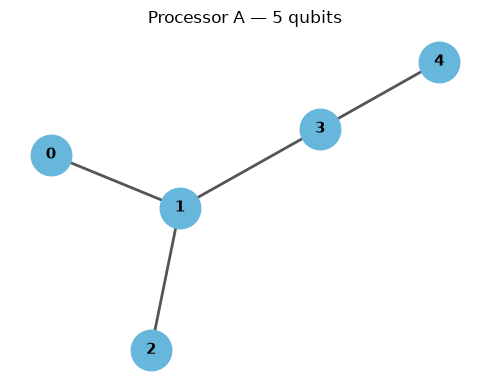

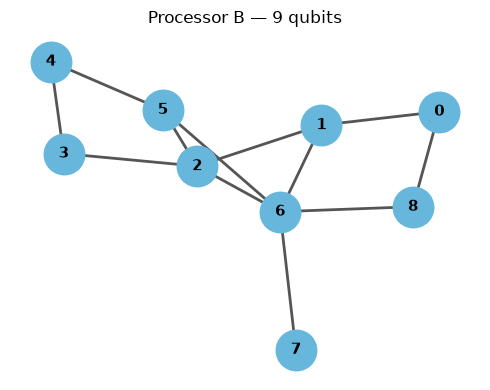

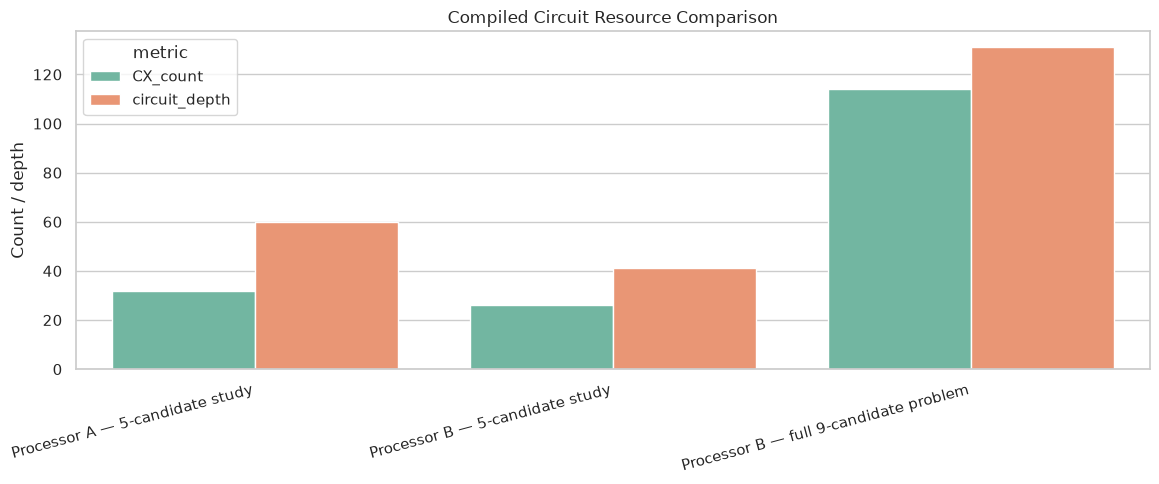

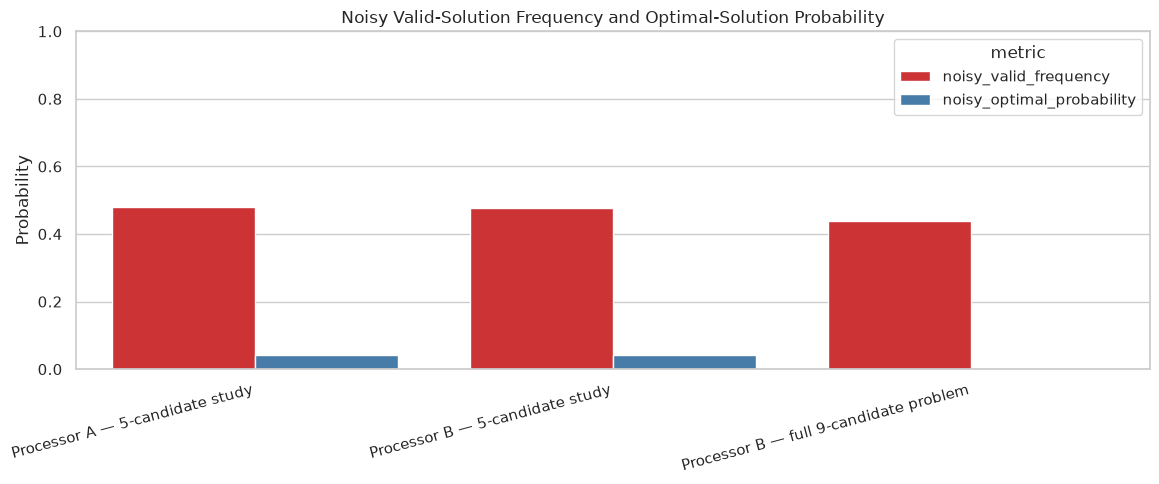

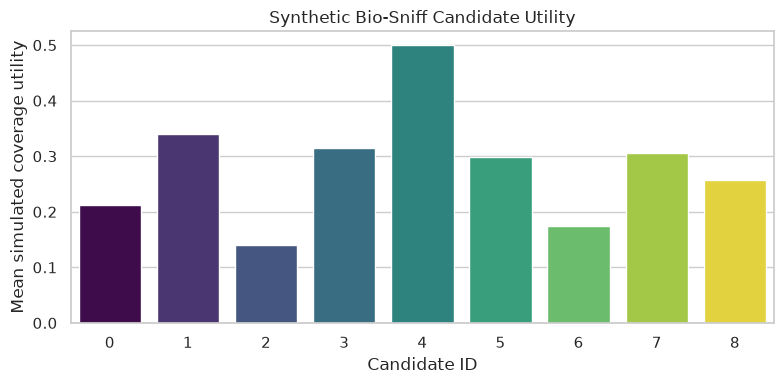


Saved:
- biosniff_processor_A_B_results.csv
- biosniff_benchmark_config.txt

Benchmark execution complete.


In [4]:
# ============================================================
# 1. HELPER FUNCTIONS FOR CLASSICAL REFERENCE AND SIMULATION
# ============================================================

def exact_classical_solution(utility, complementarity, spacing, k=K_SELECTED):
    n = len(utility)
    best_score = -np.inf
    best_selection = None

    # Exhaustively test every valid exactly-k combination.
    for selection in itertools.combinations(range(n), k):
        score = placement_reward(
            selection, utility, complementarity, spacing
        )
        if score > best_score:
            best_score = score
            best_selection = tuple(selection)

    return best_selection, float(best_score)


def sample_statistics(counts, utility, complementarity, spacing,
                      exact_selection, candidate_ids, k=K_SELECTED):
    total_shots = sum(counts.values())
    valid_shots = 0
    optimal_shots = 0
    best_score = None
    best_selection = None

    for bitstring, count in counts.items():
        bits = [int(c) for c in bitstring.replace(" ", "")[::-1]]
        selected = tuple(i for i, bit in enumerate(bits) if bit == 1)

        if len(selected) != k:
            continue

        valid_shots += count

        if tuple(sorted(selected)) == tuple(sorted(exact_selection)):
            optimal_shots += count

        score = placement_reward(
            selected, utility, complementarity, spacing
        )

        if best_score is None or score > best_score:
            best_score = score
            best_selection = selected

    return {
        "valid_frequency": valid_shots / total_shots,
        "optimal_probability": optimal_shots / total_shots,
        "best_sampled_reward": (
            best_score if best_score is not None else np.nan
        ),
        "best_sampled_candidates": (
            [candidate_ids[i] for i in best_selection]
            if best_selection is not None else None
        )
    }



from qiskit.transpiler import CouplingMap

def run_architecture(
    label, Q, params, coupling_map,
    utility, complementarity, spacing,
    candidate_ids, physical_qubits, shots=SHOTS
):
    n = len(utility)

    exact_selection, exact_score = exact_classical_solution(
        utility, complementarity, spacing
    )

    logical = qaoa_circuit(
        Q, params[0], params[1], measure=True
    )

    # Convert the edge list into a proper Qiskit CouplingMap.
    hardware_map = CouplingMap(couplinglist=coupling_map)
    hardware_map.make_symmetric()

    start = time.perf_counter()

    compiled = transpile(
        logical,
        basis_gates=BASIS_GATES,
        coupling_map=hardware_map,
        optimization_level=1,
        seed_transpiler=SEED
    )

    compile_seconds = time.perf_counter() - start
    operations = compiled.count_ops()

    # Fully connected reference with the SAME logical width.
    complete_edges = [
        (i, j)
        for i in range(n)
        for j in range(n)
        if i != j
    ]
    complete_map = CouplingMap(couplinglist=complete_edges)
    complete_map.make_symmetric()

    fully_connected_circuit = transpile(
        logical,
        basis_gates=BASIS_GATES,
        coupling_map=complete_map,
        optimization_level=1,
        seed_transpiler=SEED
    )

    compiled_cx = int(operations.get("cx", 0))
    baseline_cx = int(
        fully_connected_circuit.count_ops().get("cx", 0)
    )
    routing_cx_proxy = max(0, compiled_cx - baseline_cx)

    # Ideal sampled simulation.
    ideal_backend = AerSimulator()
    ideal_counts = ideal_backend.run(
        compiled, shots=shots, seed_simulator=SEED
    ).result().get_counts()

    ideal_stats = sample_statistics(
        ideal_counts, utility, complementarity, spacing,
        exact_selection, candidate_ids
    )

    # Noisy sampled simulation.
    noisy_backend = AerSimulator(noise_model=make_noise_model())
    noisy_counts = noisy_backend.run(
        compiled, shots=shots, seed_simulator=SEED
    ).result().get_counts()

    noisy_stats = sample_statistics(
        noisy_counts, utility, complementarity, spacing,
        exact_selection, candidate_ids
    )

    return {
        "processor": label,
        "logical_qubits": n,
        "physical_qubits_in_compiled_circuit": compiled.num_qubits,
        "coupling_edges": len(hardware_map.get_edges()) // 2,
        "classical_optimum_reward": exact_score,
        "classical_optimum_candidates": [
            candidate_ids[i] for i in exact_selection
        ],
        "ideal_best_reward": ideal_stats["best_sampled_reward"],
        "ideal_valid_frequency": ideal_stats["valid_frequency"],
        "ideal_optimal_probability": ideal_stats["optimal_probability"],
        "noisy_best_reward": noisy_stats["best_sampled_reward"],
        "noisy_valid_frequency": noisy_stats["valid_frequency"],
        "noisy_optimal_probability": noisy_stats["optimal_probability"],
        "noisy_best_candidates": noisy_stats["best_sampled_candidates"],
        "CX_count": compiled_cx,
        "CX_all_to_all_reference": baseline_cx,
        "routing_CX_overhead_proxy": routing_cx_proxy,
        "explicit_SWAP_count": int(operations.get("swap", 0)),
        "circuit_depth": compiled.depth(),
        "single_qubit_gate_count": sum(
            count for gate, count in operations.items()
            if gate in ["rz", "sx", "x"]
        ),
        "transpilation_seconds": compile_seconds,
        "shots": shots
    }


# ============================================================
# 2. CREATE THE FIVE-CANDIDATE COMMON COMPARISON
#
# Both A and B solve the SAME five-candidate, choose-three
# subproblem. This makes the connectivity comparison fair.
# ============================================================

COMMON_IDS = list(range(5))

U5 = UTILITY[:5]
C5 = COMPLEMENTARITY[:5, :5]
S5 = SPACING[:5, :5]

Q5 = build_qubo(U5, C5, S5, k=K_SELECTED)

print("Optimizing common five-candidate QAOA instance...")
params5, optimizer5 = optimize_qaoa(Q5)

print("Five-candidate QAOA parameters:", np.round(params5, 5))
print("Optimizer completed:", optimizer5.success)
print("Optimizer message:", optimizer5.message)

# Processor A: 5 physical qubits.
result_A = run_architecture(
    "Processor A — 5-candidate study",
    Q5, params5, COUPLING_A,
    U5, C5, S5, COMMON_IDS,
    physical_qubits=5
)

# Processor B: same five-candidate logical problem,
# mapped to the nine-qubit Processor B graph.
result_B_5 = run_architecture(
    "Processor B — 5-candidate study",
    Q5, params5, COUPLING_B,
    U5, C5, S5, COMMON_IDS,
    physical_qubits=9
)


# ============================================================
# 3. FULL BIOSNIFF INSTANCE: NINE CANDIDATES ON PROCESSOR B
# Processor A cannot directly host this nine-qubit encoding.
# ============================================================

Q9 = build_qubo(
    UTILITY, COMPLEMENTARITY, SPACING, k=K_SELECTED
)

print("\nOptimizing full nine-candidate QAOA instance...")
params9, optimizer9 = optimize_qaoa(Q9)

print("Nine-candidate QAOA parameters:", np.round(params9, 5))
print("Optimizer completed:", optimizer9.success)
print("Optimizer message:", optimizer9.message)

result_B_9 = run_architecture(
    "Processor B — full 9-candidate problem",
    Q9, params9, COUPLING_B,
    UTILITY, COMPLEMENTARITY, SPACING,
    list(range(9)),
    physical_qubits=9
)


# ============================================================
# 4. PRINT RESULTS TABLE
# ============================================================

results = pd.DataFrame([result_A, result_B_5, result_B_9])

columns_to_show = [
    "processor",
    "logical_qubits",
    "physical_qubits_in_compiled_circuit",
    "classical_optimum_reward",
    "ideal_best_reward",
    "noisy_best_reward",
    "noisy_valid_frequency",
    "noisy_optimal_probability",
    "CX_count",
    "routing_CX_overhead_proxy",
    "explicit_SWAP_count",
    "circuit_depth",
    "transpilation_seconds"
]

print("\n================ BENCHMARK RESULTS ================")
display(results[columns_to_show].round(4))

print("\n================ SELECTED CANDIDATES ================")
for _, row in results.iterrows():
    print(f"\n{row['processor']}")
    print("Exact classical optimum:", row["classical_optimum_candidates"])
    print("Best noisy sampled selection:", row["noisy_best_candidates"])


# ============================================================
# 5. VISUALIZE THE TWO COUPLING MAPS
# ============================================================

def plot_processor_graph(title, n, edges):
    graph = nx.Graph()
    graph.add_nodes_from(range(n))
    graph.add_edges_from(edges)

    pos = nx.spring_layout(graph, seed=SEED)

    plt.figure(figsize=(5, 4))
    nx.draw_networkx(
        graph, pos,
        node_color="#67b7dc",
        node_size=850,
        font_size=11,
        font_weight="bold",
        edge_color="#555555",
        width=2
    )
    plt.title(title)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

plot_processor_graph(
    "Processor A — 5 qubits",
    5, PROCESSOR_A_EDGES
)

plot_processor_graph(
    "Processor B — 9 qubits",
    9, PROCESSOR_B_EDGES
)


# ============================================================
# 6. COLORFUL COMPARISON GRAPHS
# ============================================================

sns.set_theme(style="whitegrid", context="notebook")

# Resource comparison. The B full-instance row uses 9 logical
# qubits, so interpret it separately from the five-qubit study.
resource_df = results.melt(
    id_vars="processor",
    value_vars=["CX_count", "circuit_depth"],
    var_name="metric",
    value_name="value"
)

plt.figure(figsize=(12, 5))
sns.barplot(
    data=resource_df,
    x="processor",
    y="value",
    hue="metric",
    palette="Set2"
)
plt.title("Compiled Circuit Resource Comparison")
plt.ylabel("Count / depth")
plt.xlabel("")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()


# Noisy solution-quality comparison.
quality_df = results.melt(
    id_vars="processor",
    value_vars=[
        "noisy_valid_frequency",
        "noisy_optimal_probability"
    ],
    var_name="metric",
    value_name="probability"
)

plt.figure(figsize=(12, 5))
sns.barplot(
    data=quality_df,
    x="processor",
    y="probability",
    hue="metric",
    palette="Set1"
)
plt.title("Noisy Valid-Solution Frequency and Optimal-Solution Probability")
plt.ylabel("Probability")
plt.ylim(0, 1)
plt.xlabel("")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()


# Compare candidate utility used by the synthetic test instance.
plt.figure(figsize=(8, 4))
sns.barplot(
    x=np.arange(9),
    y=UTILITY,
    hue=np.arange(9),
    palette="viridis",
    legend=False
)
plt.title("Synthetic Bio-Sniff Candidate Utility")
plt.xlabel("Candidate ID")
plt.ylabel("Mean simulated coverage utility")
plt.tight_layout()
plt.show()


# ============================================================
# 7. SAVE RESULTS FOR YOUR REPORT / GITHUB REPOSITORY
# ============================================================

results.to_csv("biosniff_processor_A_B_results.csv", index=False)

with open("biosniff_benchmark_config.txt", "w") as f:
    f.write(f"Seed: {SEED}\n")
    f.write(f"Shots: {SHOTS}\n")
    f.write(f"QAOA p: {QAOA_P}\n")
    f.write(f"Selected locations: {K_SELECTED}\n")
    f.write(f"Penalty: {PENALTY}\n")
    f.write(f"1-qubit noise: {P_1Q}\n")
    f.write(f"CX noise: {P_CX}\n")
    f.write(f"Readout noise: {P_READOUT}\n")
    f.write(f"Processor A edges: {PROCESSOR_A_EDGES}\n")
    f.write(f"Processor B edges: {PROCESSOR_B_EDGES}\n")
    f.write("Input data: reproducible synthetic demonstration instance\n")

print("\nSaved:")
print("- biosniff_processor_A_B_results.csv")
print("- biosniff_benchmark_config.txt")
print("\nBenchmark execution complete.")

In [3]:
import pandas as pd

results = [
    {
        "processor": "A",
        "problem": "5-candidate study",
        "logical_qubits": 5,
        "physical_qubits": 5,
        "classical_optimum": 1.1657,
        "ideal_best_reward": 1.1657,
        "noisy_best_reward": 1.1657,
        "noisy_valid_frequency": 0.4814,
        "noisy_optimal_probability": 0.0415,
        "cx_count": 32,
        "routing_cx_overhead_proxy": 12,
        "explicit_swap_count": 0,
        "circuit_depth": 60,
        "transpilation_seconds": 0.1824,
        "classical_optimum_candidates": "[2, 3, 4]",
        "best_noisy_selection": "[2, 3, 4]"
    },
    {
        "processor": "B",
        "problem": "5-candidate study",
        "logical_qubits": 5,
        "physical_qubits": 9,
        "classical_optimum": 1.1657,
        "ideal_best_reward": 1.1657,
        "noisy_best_reward": 1.1657,
        "noisy_valid_frequency": 0.4785,
        "noisy_optimal_probability": 0.0410,
        "cx_count": 26,
        "routing_cx_overhead_proxy": 6,
        "explicit_swap_count": 0,
        "circuit_depth": 41,
        "transpilation_seconds": 0.0072,
        "classical_optimum_candidates": "[2, 3, 4]",
        "best_noisy_selection": "[2, 3, 4]"
    },
    {
        "processor": "B",
        "problem": "full 9-candidate problem",
        "logical_qubits": 9,
        "physical_qubits": 9,
        "classical_optimum": 1.4525,
        "ideal_best_reward": 1.4525,
        "noisy_best_reward": 1.4525,
        "noisy_valid_frequency": 0.4380,
        "noisy_optimal_probability": 0.0046,
        "cx_count": 114,
        "routing_cx_overhead_proxy": 42,
        "explicit_swap_count": 0,
        "circuit_depth": 131,
        "transpilation_seconds": 0.0112,
        "classical_optimum_candidates": "[1, 6, 8]",
        "best_noisy_selection": "[1, 6, 8]"
    }
]

found = pd.DataFrame(results)
display(found)

,processor,problem,logical_qubits,physical_qubits,classical_optimum,ideal_best_reward,noisy_best_reward,noisy_valid_frequency,noisy_optimal_probability,cx_count,routing_cx_overhead_proxy,explicit_swap_count,circuit_depth,transpilation_seconds,classical_optimum_candidates,best_noisy_selection
0,A,5-candidate study,5,5,1.1657,1.1657,1.1657,0.4814,0.0415,32,12,0,60,0.1824,"[2, 3, 4]","[2, 3, 4]"
1,B,5-candidate study,5,9,1.1657,1.1657,1.1657,0.4785,0.0410,26,6,0,41,0.0072,"[2, 3, 4]","[2, 3, 4]"
2,B,full 9-candidate problem,9,9,1.4525,1.4525,1.4525,0.4380,0.0046,114,42,0,131,0.0112,"[1, 6, 8]","[1, 6, 8]"


In [4]:
from google.colab import files

csv_path = "/content/biosniff_processor_A_B_results.csv"
found.to_csv(csv_path, index=False)

print("CSV saved:", csv_path)
files.download(csv_path)

CSV saved: /content/biosniff_processor_A_B_results.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:
config_text = """
Bio-Sniff QAOA Synthetic Architecture Benchmark
================================================

Data status:
Synthetic placement scenarios and scores; not physical field measurements.

Problem:
Select exactly 3 locations from 9 candidate locations.

Objective weights:
Utility = 0.60
Complementarity = 0.25
Spatial distribution = 0.15

QAOA:
p = 1
Shots = 4096
Random seed = 42
Optimizer = COBYLA
Maximum iterations per optimization = 60

Noise assumptions:
Single-qubit depolarizing probability = 0.001
CX depolarizing probability = 0.005
Readout bit-flip probability = 0.01

Transpilation:
Optimization level = 1
Basis gates = rz, sx, x, cx
Random seed = 42

Processor A:
5-qubit study configuration
Edges: (0,1), (1,2), (1,3), (3,4)

Processor B:
9-qubit study configuration
Edges: (0,1), (1,2), (1,6), (2,3), (2,6), (2,5),
       (3,4), (4,5), (5,6), (6,7), (6,8), (8,0)

Validation:
Compared against exact classical evaluation of valid selections.

Limitations:
Synthetic placement inputs; no real-field validation or quantum advantage claimed.
"""

config_path = "/content/biosniff_benchmark_config.txt"

with open(config_path, "w", encoding="utf-8") as f:
    f.write(config_text.strip() + "\n")

print("Configuration saved:", config_path)
files.download(config_path)

Configuration saved: /content/biosniff_benchmark_config.txt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:
from pathlib import Path

for filename in [
    "biosniff_processor_A_B_results.csv",
    "biosniff_benchmark_config.txt"
]:
    path = Path("/content") / filename
    print(filename, "—", "EXISTS" if path.exists() else "MISSING")

biosniff_processor_A_B_results.csv — EXISTS
biosniff_benchmark_config.txt — EXISTS
